# Cloud workload forecasting: analysis

Reviewer-facing narrative for the leakage-safe forecasting pipeline (`cwfc`). Everything below reads the
artifacts written by `cwfc.predict`, `cwfc.benchmark` and `cwfc.evaluate`; no foundation-model inference or
model search is repeated here. Units: CPU in percent, errors in percentage points (pp), time in hours from trace start.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cwfc.data import build_panel, load_metadata, load_readings
from cwfc.targets import EXTRA_TARGETS, holdout_split, series
from cwfc.fm import CONTAMINATION
from cwfc.models import LightGBMPanel

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ART, FIG, DATA = ROOT / "reports" / "artifacts", ROOT / "reports" / "figures", ROOT / "challenge_data"
FIG.mkdir(parents=True, exist_ok=True)

NEEDED = ["selection.json", "intervals.csv", "tradeoff.csv", "capacity_plan.csv", "holdout_eval.json",
          "benchmark_summary.csv", "benchmark_cpu.csv", "benchmark_count.csv", "dm_matrix.csv", "latency.csv"]
missing = [f for f in NEEDED if not (ART / f).is_file()]
if missing:
    raise FileNotFoundError(
        f"missing artifacts {missing}. Run first:\n"
        "  python -m cwfc.predict --data challenge_data --output predictions.csv\n"
        "  python -m cwfc.benchmark --data challenge_data --artifacts reports/artifacts --with-fm\n"
        "  python -m cwfc.evaluate --data challenge_data   (one-shot holdout scoring)")

ACCENT, GREY, LIGHT, FLAG = "#0b6e99", "#6b7280", "#c9ced6", "#d9622b"
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "axes.grid": True, "grid.alpha": 0.25})
CPU, COUNT, H = "aggregate_cpu_utilization", "active_vm_count", 24
REGIME = (53, 72)  # step indices of the bump documented in devlog D1

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

readings, metadata = load_readings(DATA), load_metadata(DATA)
panel = build_panel(readings, metadata)
train, holdout_ts = holdout_split(panel, H)
sel = json.loads((ART / "selection.json").read_text())
hours = (panel.timestamps - panel.timestamps[0]) / 3600
cpu = series(panel, CPU)
n_tr = train.T
print(f"{panel.avg.shape[0]:,} VMs x {panel.T} steps; train {n_tr}, holdout {H}")

10,000 VMs x 134 steps; train 110, holdout 24


## 1. Data contract and the constant VM count

**Why it matters operationally:** a forecast is only as trustworthy as the feed behind it. Before modelling we
check the grid, duplicates and invalid readings, and we establish what `active_vm_count` actually is, because it
decides whether that target needs a model at all.

In [2]:
print(pd.Series(sel["data_report"]).to_string())
count = series(panel, COUNT)
created = pd.to_numeric(metadata["timestamp_vm_created"])
deleted = pd.to_numeric(metadata["timestamp_vm_deleted"])
window_end = int(panel.timestamps[-1])
proof = pd.Series({
    "min active_vm_count": count.min(), "max active_vm_count": count.max(),
    "VMs in metadata": len(metadata),
    "VMs created after trace start": int((created > panel.timestamps[0]).sum()),
    "VMs deleted inside the window (analysis only, never a feature)": int((deleted <= window_end).sum()),
})
print(); print(proof.to_string())

n_rows                1340000
n_vms                   10000
n_timestamps              134
step_seconds              300
missing_timestamps         []
duplicate_rows              0
invalid_readings            0
order_violations            0

min active_vm_count                                               10000.0
max active_vm_count                                               10000.0
VMs in metadata                                                   10000.0
VMs created after trace start                                         0.0
VMs deleted inside the window (analysis only, never a feature)        0.0


`min == max`: the count is a constant. The reason is how the dataset was cut, not how the cloud behaves: only
VMs with complete traces were kept, so every VM exists from the first timestamp and none disappears inside the
window (counts above). The constant is a selection artefact, so the persistence forecast is exact and any
model that deviates can only be worse. Metadata fields that summarise a VM's whole lifetime (`avg_cpu`,
`max_cpu`, `p95_max_cpu`, `timestamp_vm_deleted`) are used here for this proof only and are never model features
(devlog D2).

## 2. Aggregate CPU: boundary, regime and memory

**Why it matters operationally:** the level and its noise set how much headroom is needed; the regime and
autocorrelation say how far ahead a "now" reading stays informative.

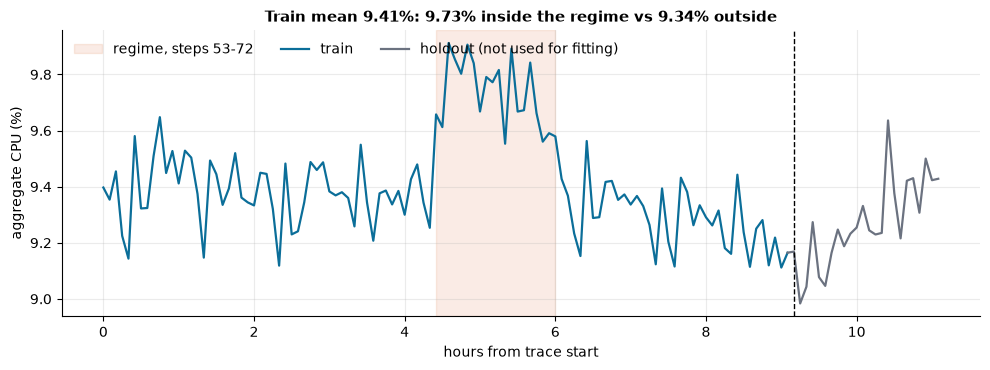

In [3]:
mu_in = cpu[REGIME[0]:REGIME[1] + 1].mean(); mu_out = np.delete(cpu[:n_tr], np.arange(REGIME[0], REGIME[1] + 1)).mean()
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.axvspan(hours[REGIME[0]], hours[REGIME[1]], color=FLAG, alpha=0.12, label=f"regime, steps {REGIME[0]}-{REGIME[1]}")
ax.plot(hours[:n_tr], cpu[:n_tr], color=ACCENT, lw=1.6, label="train")
ax.plot(hours[n_tr - 1:], cpu[n_tr - 1:], color=GREY, lw=1.6, label="holdout (not used for fitting)")
ax.axvline(hours[n_tr], color="k", ls="--", lw=1)
ax.set(xlabel="hours from trace start", ylabel="aggregate CPU (%)",
       title=f"Train mean {np.nanmean(cpu[:n_tr]):.2f}%: {mu_in:.2f}% inside the regime vs {mu_out:.2f}% outside")
ax.legend(frameon=False, loc="upper left", ncol=3)
save(fig, "02_aggregate_cpu_boundary_regime")

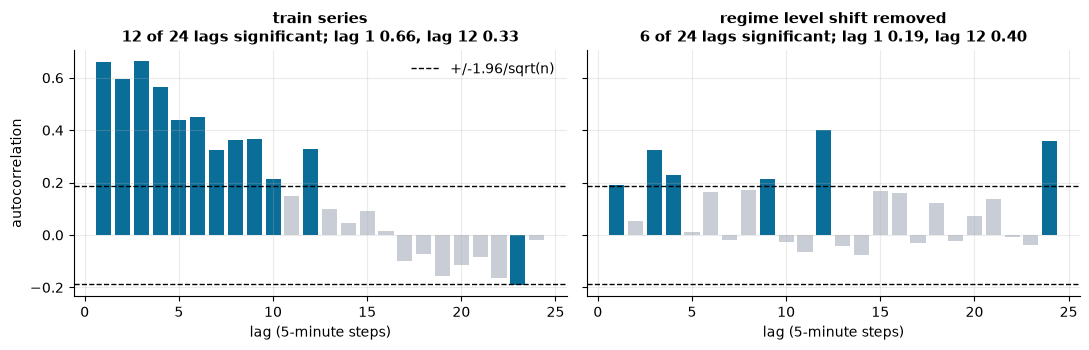

significant lags, full train: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 23]
significant lags, regime removed: [1, 3, 4, 9, 12, 24]
Trace spans 11.1 hours: too short to observe or estimate any daily seasonality.


In [4]:
def acf_of(v, nlag=24):
    v = v - v.mean()
    return np.array([float(v[k:] @ v[:-k] / (v @ v)) for k in range(1, nlag + 1)])

y = cpu[:n_tr].copy()
idx = np.arange(REGIME[0], REGIME[1] + 1); out = np.setdiff1d(np.arange(n_tr), idx)
y_dm = y.copy(); y_dm[idx] -= y[idx].mean(); y_dm[out] -= y[out].mean()   # remove the regime level shift
a_full, a_dm = acf_of(y), acf_of(y_dm)
band = 1.96 / np.sqrt(n_tr)
sig = lambda a: np.flatnonzero(np.abs(a) > band) + 1
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, a, name in zip(axs, [a_full, a_dm], ["train series", "regime level shift removed"]):
    ax.bar(range(1, 25), a, color=[ACCENT if abs(v) > band else LIGHT for v in a])
    ax.axhline(band, color="k", ls="--", lw=1); ax.axhline(-band, color="k", ls="--", lw=1, label="+/-1.96/sqrt(n)")
    ax.set(xlabel="lag (5-minute steps)", title=f"{name}"+chr(10)+f"{len(sig(a))} of 24 lags significant; lag 1 {a[0]:.2f}, lag 12 {a[11]:.2f}")
axs[0].set_ylabel("autocorrelation"); axs[0].legend(frameon=False)
save(fig, "02_acf")
print("significant lags, full train:", sig(a_full).tolist()); print("significant lags, regime removed:", sig(a_dm).tolist())
span_h = (panel.timestamps[-1] - panel.timestamps[0]) / 3600
print(f"Trace spans {span_h:.1f} hours: too short to observe or estimate any daily seasonality.")

Autocorrelation is persistent rather than quickly decaying: it stays outside the band for roughly an hour of
lags. Part of that is the regime itself, a 20-step level shift that makes neighbouring points alike; the right
panel removes that shift (regime mean inside the window, overall mean outside) and shows what is left: a much weaker
and patchier autocorrelation (see the significant-lag counts in the panel titles). The trace is only hours long, so a daily cycle cannot be identified and no seasonal
model is offered. Both ACFs use the training window only.

## 3. Who uses the CPU: VM level and segments

**Why it matters operationally:** capacity is bought per VM class, so we need to know whether the fleet is
homogeneous. A skewed fleet makes the mean differ from the typical VM (section 7 returns to this only as a caution about median-based bottom-up forecasts; a cross-sectional skew is not the same as predictive skew within a VM).

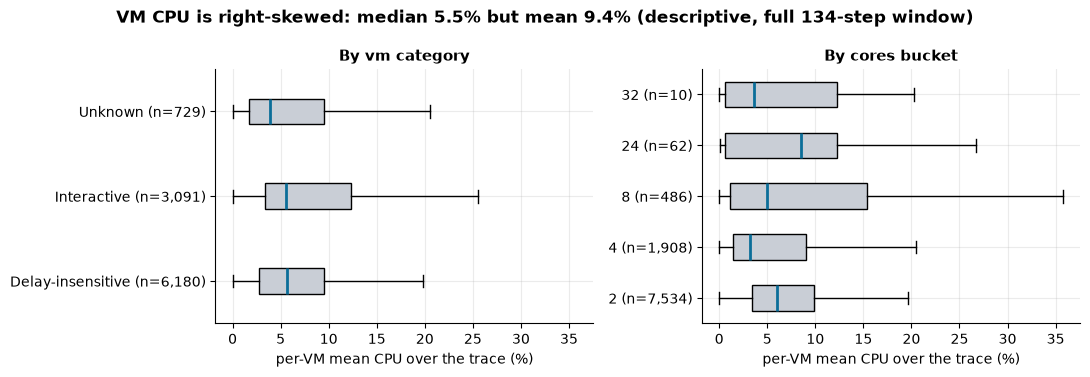

In [5]:
vm_mean = np.nanmean(panel.avg, axis=1)
stat = panel.static.assign(vm_mean=vm_mean)
stat["cores_bucket"] = stat["cores"].astype(str)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for ax, col in zip(axs, ["vm_category", "cores_bucket"]):
    groups = sorted(stat[col].unique(), key=lambda g: (float(g) if g.isdigit() else g))
    ax.boxplot([stat.loc[stat[col] == g, "vm_mean"] for g in groups], orientation='horizontal', showfliers=False,
               patch_artist=True, boxprops=dict(facecolor=LIGHT), medianprops=dict(color=ACCENT, lw=2))
    ax.set_yticklabels([f"{g} (n={int((stat[col] == g).sum()):,})" for g in groups])
    ax.set(xlabel="per-VM mean CPU over the trace (%)", title=f"By {col.replace('_', ' ')}")
fig.suptitle(f"VM CPU is right-skewed: median {stat.vm_mean.median():.1f}% but mean {stat.vm_mean.mean():.1f}% (descriptive, full {panel.T}-step window)", fontweight="bold")
save(fig, "03_vm_cpu_distribution")

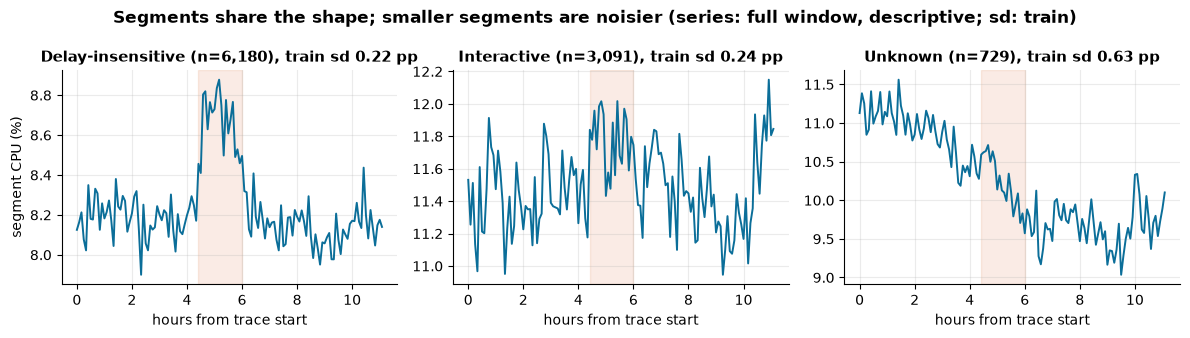

In [6]:
cats = panel.static["vm_category"].to_numpy()
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4), sharex=True)
for ax, c in zip(axs, sorted(np.unique(cats))):
    s = series(panel.subset(cats == c), CPU)
    ax.plot(hours, s, color=ACCENT, lw=1.4); ax.axvspan(hours[REGIME[0]], hours[REGIME[1]], color=FLAG, alpha=0.12)
    ax.set(title=f"{c} (n={int((cats == c).sum()):,}), train sd {np.nanstd(s[:n_tr]):.2f} pp", xlabel="hours from trace start")
axs[0].set_ylabel("segment CPU (%)")
fig.suptitle("Segments share the shape; smaller segments are noisier (series: full window, descriptive; sd: train)", fontweight="bold")
save(fig, "03_segment_series")

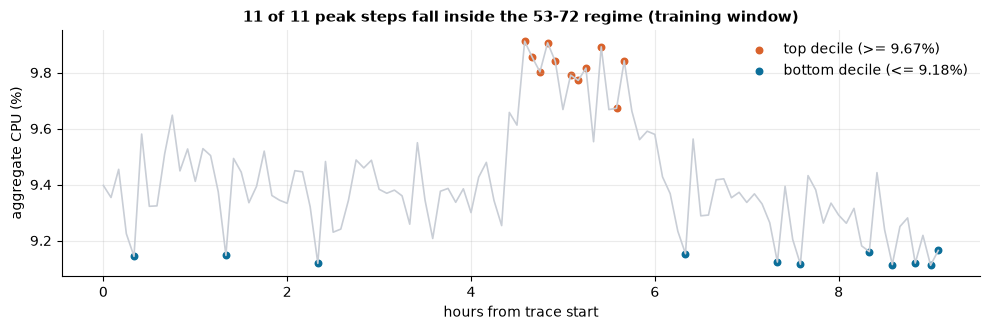

peak steps: [55, 56, 57, 58, 59, 61, 62, 63, 65, 67, 68]
low steps: [4, 16, 28, 76, 88, 91, 100, 103, 106, 108, 109]


In [7]:
q_hi, q_lo = np.nanquantile(cpu[:n_tr], 0.9), np.nanquantile(cpu[:n_tr], 0.1)  # deciles of the training window
top, bot = np.flatnonzero(cpu[:n_tr] >= q_hi), np.flatnonzero(cpu[:n_tr] <= q_lo)
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(hours[:n_tr], cpu[:n_tr], color=LIGHT, lw=1.2)
ax.scatter(hours[top], cpu[top], color=FLAG, s=22, label=f"top decile (>= {q_hi:.2f}%)")
ax.scatter(hours[bot], cpu[bot], color=ACCENT, s=22, label=f"bottom decile (<= {q_lo:.2f}%)")
ax.set(xlabel="hours from trace start", ylabel="aggregate CPU (%)",
       title=f"{int((top >= REGIME[0]).__and__(top <= REGIME[1]).sum())} of {len(top)} peak steps fall inside the {REGIME[0]}-{REGIME[1]} regime (training window)")
ax.legend(frameon=False)
save(fig, "03_peak_low_periods")
print("peak steps:", top.tolist()); print("low steps:", bot.tolist())

## 4. Capacity-oriented targets

**Why it matters operationally:** capacity is consumed in cores, not in VM averages. `core_weighted_cpu`
weights each VM by its cores; `peak_core_demand` (cores) uses each VM's interval maximum and is what a
peak-protecting plan would size to. The `>24` bucket is assumed to be 32 cores (devlog D6).

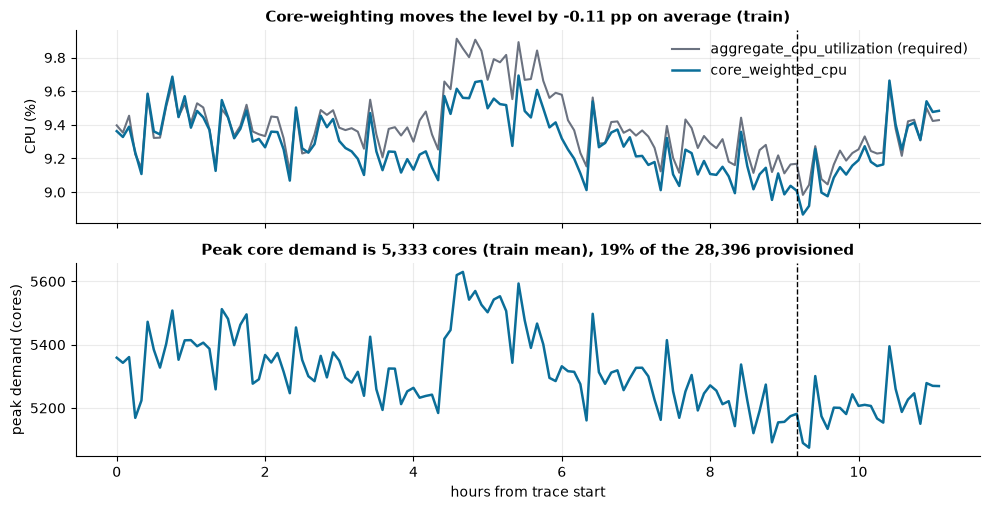

                   aggregate_cpu  core_weighted_cpu  peak_core_demand
aggregate_cpu              1.000              0.899             0.869
core_weighted_cpu          0.899              1.000             0.915
peak_core_demand           0.869              0.915             1.000


In [8]:
ext = {t: series(panel, t) for t in EXTRA_TARGETS}
fig, axs = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True)
axs[0].plot(hours, cpu, color=GREY, lw=1.5, label="aggregate_cpu_utilization (required)")
axs[0].plot(hours, ext["core_weighted_cpu"], color=ACCENT, lw=1.8, label="core_weighted_cpu")
axs[0].set(ylabel="CPU (%)", title=f"Core-weighting moves the level by {np.mean(ext['core_weighted_cpu'][:n_tr] - cpu[:n_tr]):+.2f} pp on average (train)")
axs[0].legend(frameon=False)
axs[1].plot(hours, ext["peak_core_demand"], color=ACCENT, lw=1.8)
axs[1].set(ylabel="peak demand (cores)", xlabel="hours from trace start",
           title=f"Peak core demand is {np.nanmean(ext['peak_core_demand'][:n_tr]):,.0f} cores (train mean), {np.nanmean(ext['peak_core_demand'][:n_tr]) / (panel.static.cores.sum() / 100):.0f}% of the {panel.static.cores.sum():,} provisioned")
for a in axs: a.axvline(hours[n_tr], color="k", ls="--", lw=1)
save(fig, "04_extra_targets")
print(pd.DataFrame({"aggregate_cpu": cpu, **ext}).iloc[:n_tr].corr().round(3))

## 5. Model comparison on the training folds

**Why it matters operationally:** a model earns a place in production only if it beats a trivial rule with
statistical evidence. All numbers are mean absolute error over 20 rolling origins inside the training window
(`benchmark_summary.csv`); the holdout is not involved.

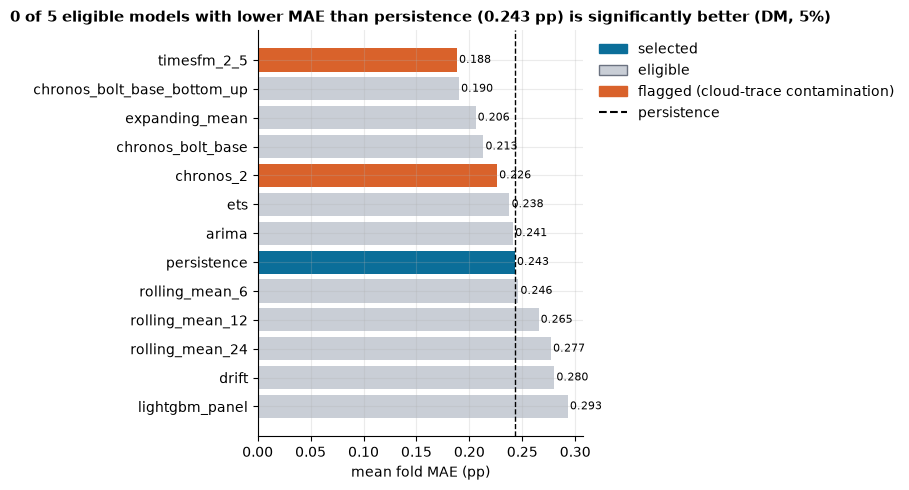

,model,complexity,mae,rmse,mase,mean_error,seconds,flagged,eligible
12,timesfm_2_5,4,0.1882,0.2339,1.5541,-0.0469,15.1507,True,False
11,chronos_bolt_base_bottom_up,4,0.1902,0.2442,1.5701,0.0639,45.2716,False,True
10,expanding_mean,1,0.2058,0.2427,1.6993,0.0026,0.1936,False,True
9,chronos_bolt_base,4,0.2132,0.2558,1.7601,-0.0722,4.6801,False,True
8,chronos_2,4,0.2261,0.2765,1.8669,-0.0933,3.4235,True,False
7,ets,2,0.2379,0.2888,1.9639,-0.0980,1.3901,False,True
6,arima,2,0.2413,0.2907,1.9922,-0.0681,3.8388,False,True
5,persistence,0,0.2430,0.2972,2.0059,-0.1283,0.1846,False,True
4,rolling_mean_6,1,0.2462,0.2961,2.0329,-0.0987,0.2000,False,True
3,rolling_mean_12,1,0.2653,0.3080,2.1906,-0.0986,0.2303,False,True


In [9]:
bs = pd.read_csv(ART / "benchmark_summary.csv").sort_values("mae", ascending=False).reset_index(drop=True)
chosen = sel["targets"][CPU]["selected"]
pers = bs.loc[bs.model == "persistence", "mae"].iloc[0]
dm_raw = pd.read_csv(ART / "dm_matrix.csv", index_col=0)
better = bs[(bs.eligible) & (bs.mae < pers)].model.tolist()
n_better_sig = int(sum(dm_raw.loc["persistence", m] < 0.05 for m in better))
title = f"{n_better_sig} of {len(better)} eligible models with lower MAE than persistence ({pers:.3f} pp) is significantly better (DM, 5%)"
col = [FLAG if f else (ACCENT if m == chosen else LIGHT) for m, f in zip(bs.model, bs.flagged)]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(bs.model, bs.mae, color=col)
ax.axvline(pers, color="k", ls="--", lw=1, label=f"persistence {pers:.3f}")
for i, v in enumerate(bs.mae): ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8)
ax.set(xlabel="mean fold MAE (pp)", title=title)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=ACCENT, label="selected"), Patch(facecolor=LIGHT, edgecolor=GREY, label="eligible"),
                   Patch(color=FLAG, label="flagged (cloud-trace contamination)"),
                   plt.Line2D([], [], color="k", ls="--", label="persistence")], frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
save(fig, "05_model_mae")
bs.sort_values("mae").round(4)

Caution: with ~20 overlapping folds the DM test has low power, so not significant is not the same as equal.


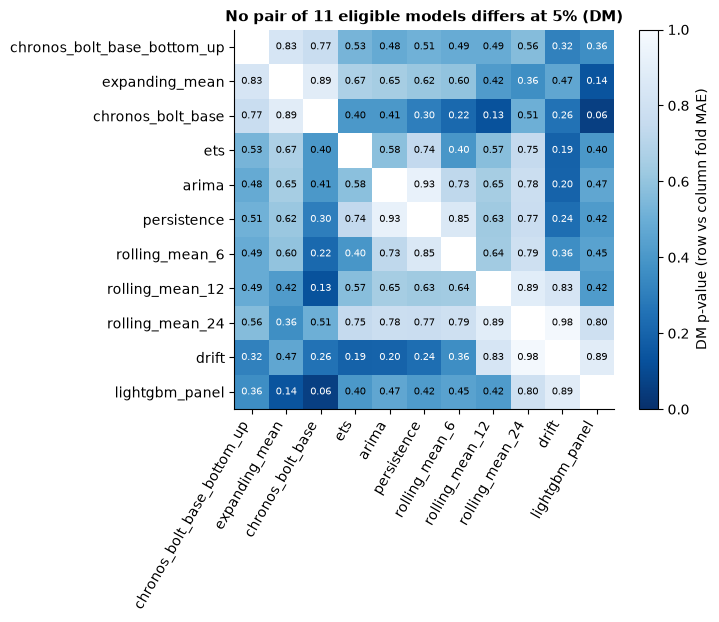

Selection for aggregate_cpu_utilization (CLI default candidate set: persistence, expanding_mean, rolling_mean_6, rolling_mean_12, rolling_mean_24, drift, ets, arima):
  selected = persistence; reason: not significantly worse than expanding_mean (DM p=0.617)
Selection for active_vm_count: persistence; reason: lowest MAE; no simpler candidates


In [10]:
dm = pd.read_csv(ART / "dm_matrix.csv", index_col=0)
order = bs[bs.eligible].sort_values("mae").model.tolist(); dm = dm.loc[order, order]
fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(dm.values.astype(float), cmap="Blues_r", vmin=0, vmax=1)
ax.set_xticks(range(len(order)), order, rotation=60, ha="right"); ax.set_yticks(range(len(order)), order)
for i in range(len(order)):
    for j in range(len(order)):
        v = dm.values[i, j]
        if np.isfinite(v): ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="w" if v < 0.4 else "k")
ax.grid(False); fig.colorbar(im, label="DM p-value (row vs column fold MAE)")
n_pairs = len(order) * (len(order) - 1) // 2
n_sig = int((dm.values[np.tril_indices(len(order), -1)] < 0.05).sum())
ax.set_title("No pair of " + str(len(order)) + " eligible models differs at 5% (DM)" if n_sig == 0 else f"{n_sig} of {n_pairs} model pairs differ at 5% (DM)")
print("Caution: with ~20 overlapping folds the DM test has low power, so not significant is not the same as equal.")
save(fig, "05_dm_heatmap")
t = sel["targets"][CPU]
print(f"Selection for {CPU} (CLI default candidate set: {', '.join(t['candidates'])}):")
print(f"  selected = {t['selected']}; reason: {t['reason']}")
print(f"Selection for {COUNT}: {sel['targets'][COUNT]['selected']}; reason: {sel['targets'][COUNT]['reason']}")

Selection rule (devlog D8): lowest mean fold MAE, unless a simpler model is not significantly worse
(Diebold-Mariano, Newey-West variance, 5%). With ~20 overlapping folds almost no pair differs significantly, so
the simplest adequate model is chosen. The selection record above comes from the default CLI candidate set;
the heatmap covers the wider benchmark among eligible models.

## 6. Error analysis

**Why it matters operationally:** an average error hides when the forecast fails. We look at the horizon, at
the sign of the error across origins, and at high-load steps, which is where under-provisioning hurts.

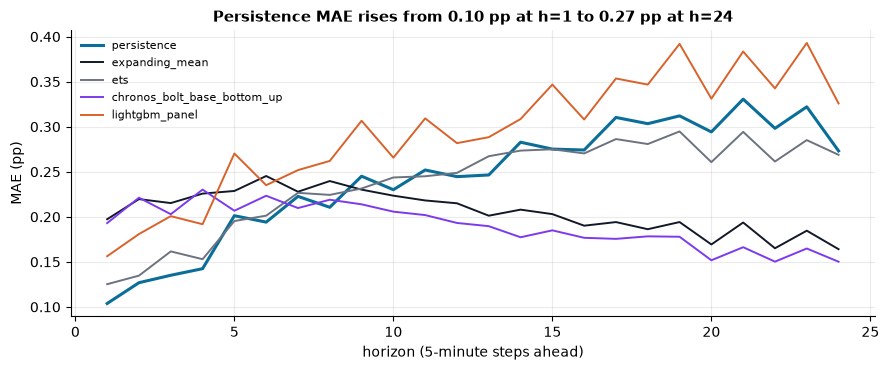

MAE of Chronos bottom-up / expanding mean falls with h (0.19 -> 0.15 pp, 0.20 -> 0.16 pp). This is mostly a fold-composition artefact: 95% of the origins have their h=24 target after the bump, where level-anchored forecasts are accurate, while h=1 targets of early origins sit on the bump.


In [11]:
bt = pd.read_csv(ART / "benchmark_cpu.csv"); bt["err"] = bt.actual - bt.pred
show = [m for m in ["persistence", "expanding_mean", "ets", "chronos_bolt_base_bottom_up", "lightgbm_panel"] if m in set(bt.model)]
sty = {"persistence": ACCENT, "expanding_mean": "#111827", "ets": GREY, "chronos_bolt_base_bottom_up": "#7c3aed", "lightgbm_panel": FLAG}
fig, ax = plt.subplots(figsize=(9, 3.8))
hz = bt.assign(a=bt.err.abs()).pivot_table(index="h", columns="model", values="a")
for m in show:
    g = hz[m]
    ax.plot(g.index, g.values, color=sty[m], lw=2.2 if m == "persistence" else 1.4, label=m)
ax.set(xlabel="horizon (5-minute steps ahead)", ylabel="MAE (pp)",
       title=f"Persistence MAE rises from {hz.persistence.iloc[0]:.2f} pp at h=1 to {hz.persistence.iloc[-1]:.2f} pp at h={H}")
ax.legend(frameon=False, fontsize=8)
save(fig, "06_mae_by_horizon")
late = np.mean([o + H - 1 > REGIME[1] for o in bt.origin.unique()])
print(f"MAE of Chronos bottom-up / expanding mean falls with h ({hz.chronos_bolt_base_bottom_up.iloc[0]:.2f} -> {hz.chronos_bolt_base_bottom_up.iloc[-1]:.2f} pp, "
      f"{hz.expanding_mean.iloc[0]:.2f} -> {hz.expanding_mean.iloc[-1]:.2f} pp). This is mostly a fold-composition artefact: "
      f"{late:.0%} of the origins have their h={H} target after the bump, where level-anchored forecasts are accurate, "
      "while h=1 targets of early origins sit on the bump.")

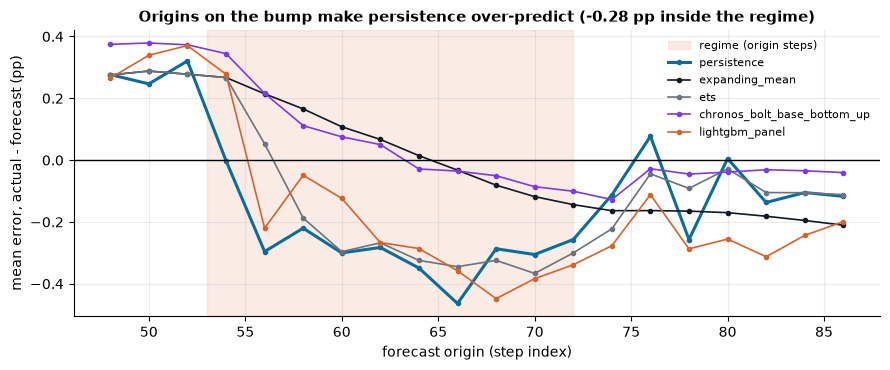

10 of 20 fold origins lie inside the 53-72 regime.


In [12]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.axvspan(*REGIME, color=FLAG, alpha=0.12, label="regime (origin steps)")
for m in show:
    g = bt[bt.model == m].groupby("origin").err.mean()
    ax.plot(g.index, g.values, marker="o", ms=3, color=sty[m], lw=2.2 if m == "persistence" else 1.2, label=m)
ax.axhline(0, color="k", lw=1)
p_reg = bt[(bt.model == "persistence") & bt.origin.between(*REGIME)].err.mean()
ax.set(xlabel="forecast origin (step index)", ylabel="mean error, actual - forecast (pp)",
       title=f"Origins on the bump make persistence over-predict ({p_reg:+.2f} pp inside the regime)")
ax.legend(frameon=False, fontsize=8)
save(fig, "06_mean_error_by_origin")
orig = np.sort(bt.origin.unique()); n_in = int(((orig >= REGIME[0]) & (orig <= REGIME[1])).sum())
print(f"{n_in} of {len(orig)} fold origins lie inside the {REGIME[0]}-{REGIME[1]} regime.")

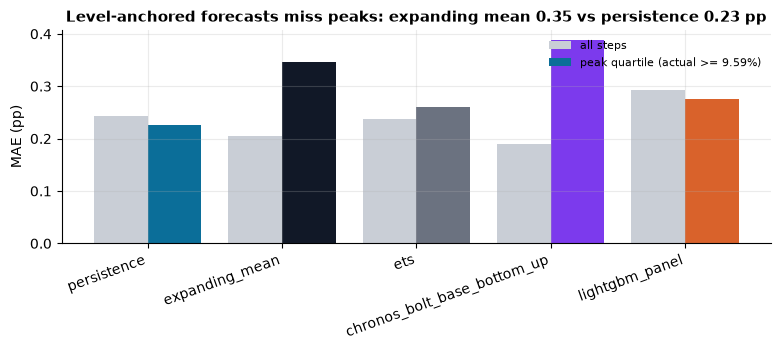

Persistence peak-quartile MAE (0.23 pp) vs its all-step MAE (0.24 pp); expanding mean 0.35 vs 0.21. Persistence follows the current level; level-anchored models lag behind peaks.


,all_steps,peak_quartile
model,,
persistence,0.243,0.225
expanding_mean,0.206,0.346
ets,0.238,0.260
chronos_bolt_base_bottom_up,0.190,0.388
lightgbm_panel,0.293,0.276


In [13]:
thr = bt.actual.quantile(0.75)
pk = bt[bt.actual >= thr].groupby("model").err.apply(lambda e: e.abs().mean())
al = bt.groupby("model").err.apply(lambda e: e.abs().mean())
cmp_ = pd.DataFrame({"all_steps": al, "peak_quartile": pk}).loc[show]
fig, ax = plt.subplots(figsize=(8, 3.6)); x = np.arange(len(show))
ax.bar(x - 0.2, cmp_.all_steps, 0.4, color=LIGHT, label="all steps")
ax.bar(x + 0.2, cmp_.peak_quartile, 0.4, color=[sty[m] for m in show], label=f"peak quartile (actual >= {thr:.2f}%)")
ax.set_xticks(x, show, rotation=20, ha="right")
ax.set(ylabel="MAE (pp)", title=f"Level-anchored forecasts miss peaks: expanding mean {cmp_.peak_quartile.expanding_mean:.2f} vs persistence {cmp_.peak_quartile.persistence:.2f} pp")
ax.legend(frameon=False, fontsize=8)
save(fig, "06_peak_quartile_error")
print(f"Persistence peak-quartile MAE ({cmp_.peak_quartile.persistence:.2f} pp) vs its all-step MAE ({cmp_.all_steps.persistence:.2f} pp); "
      f"expanding mean {cmp_.peak_quartile.expanding_mean:.2f} vs {cmp_.all_steps.expanding_mean:.2f}. Persistence follows the current level; level-anchored models lag behind peaks.")
cmp_.round(3)

## 7. Foundation models

**Why it matters operationally:** zero-shot models are tempting because they need no training, but a model
pretrained on public cloud traces may have seen the evaluation workload. Contaminated models are benchmarked
for reference and excluded from selection.

In [14]:
ct = pd.DataFrame([{"model_id": k, "flagged": v[0], "note": v[1]} for k, v in CONTAMINATION.items()])
pd.set_option("display.max_colwidth", 140); ct

,model_id,flagged,note
0,amazon/chronos-bolt-base,False,"corpus undocumented, no cloud traces named: https://huggingface.co/amazon/chronos-bolt-base"
1,amazon/chronos-2,True,"pretrained on Azure VM 2017, Alibaba 2018, Borg 2011: https://arxiv.org/html/2510.15821"
2,google/timesfm-2.5-200m-pytorch,True,GiftEvalPretrain includes CloudOps TSF (Azure/Borg/Alibaba): https://arxiv.org/html/2410.10393


In [15]:
skew = np.nanmean(np.nanmedian(train.avg, axis=1)) - np.nanmean(train.avg)
fm_rows = bs[bs.model.str.contains("chronos|timesfm")].sort_values("mae")
print(f"Cross-sectional check: the mean over VMs of each VM median CPU is {skew:+.2f} pp vs the true mean (right-skewed fleet). Medians are a biased route to a fleet mean, so a bottom-up "
      "forecast built from medians is biased low (devlog D17; an analogy, not a re-run of that experiment); the mean is approximated from the 0.1-0.9 quantile grid (D19).")
fm_rows[["model", "mae", "mean_error", "flagged", "seconds"]].round(3)

Cross-sectional check: the mean over VMs of each VM median CPU is -0.64 pp vs the true mean (right-skewed fleet). Medians are a biased route to a fleet mean, so a bottom-up forecast built from medians is biased low (devlog D17; an analogy, not a re-run of that experiment); the mean is approximated from the 0.1-0.9 quantile grid (D19).


,model,mae,mean_error,flagged,seconds
12,timesfm_2_5,0.188,-0.047,True,15.151
11,chronos_bolt_base_bottom_up,0.190,0.064,False,45.272
9,chronos_bolt_base,0.213,-0.072,False,4.680
8,chronos_2,0.226,-0.093,True,3.423


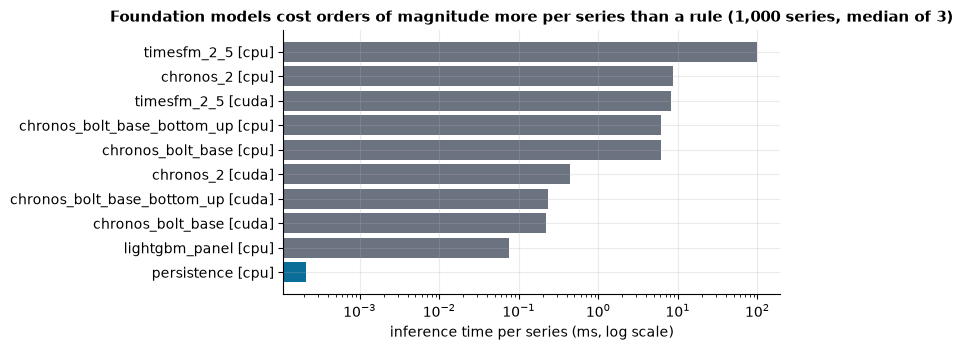

,model,device,n_series,seconds,ms_per_series
0,persistence,cpu,1000,0.0002,0.0002
1,lightgbm_panel,cpu,1000,0.0758,0.0758
2,chronos_bolt_base,cuda,1000,0.2225,0.2225
4,chronos_bolt_base_bottom_up,cuda,1000,0.2345,0.2345
3,chronos_2,cuda,1000,0.4361,0.4361
6,chronos_bolt_base,cpu,1000,6.0770,6.0770
8,chronos_bolt_base_bottom_up,cpu,1000,6.1058,6.1058
5,timesfm_2_5,cuda,1000,8.1269,8.1269
7,chronos_2,cpu,1000,8.6103,8.6103
9,timesfm_2_5,cpu,1000,99.8254,99.8254


In [16]:
lat = pd.read_csv(ART / "latency.csv"); lat["label"] = lat.model + " [" + lat.device + "]"
lat = lat.sort_values("ms_per_series")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(lat.label, lat.ms_per_series, color=[ACCENT if m == "persistence" else GREY for m in lat.model]); ax.set_xscale("log")
ax.set(xlabel="inference time per series (ms, log scale)", title=f"Foundation models cost orders of magnitude more per series than a rule ({int(lat.n_series.iloc[0]):,} series, median of 3)")
save(fig, "07_latency")
lat[["model", "device", "n_series", "seconds", "ms_per_series"]].round(4)

Latency covers inference only (weights loaded, warm-up excluded); LightGBM is timed after fitting and excludes feature construction (which would add to its cost), and its fold cost is in the `seconds` column above (training dominates). For a fleet-level forecast the cost is
negligible either way; it matters only for per-VM bottom-up forecasting at fleet scale.

## 8. What the LightGBM panel model learns

**Why it matters operationally:** importance shows which VM attributes and lags carry signal, which tells an
operator what telemetry is worth collecting. One fit on the training panel; the holdout is not involved.

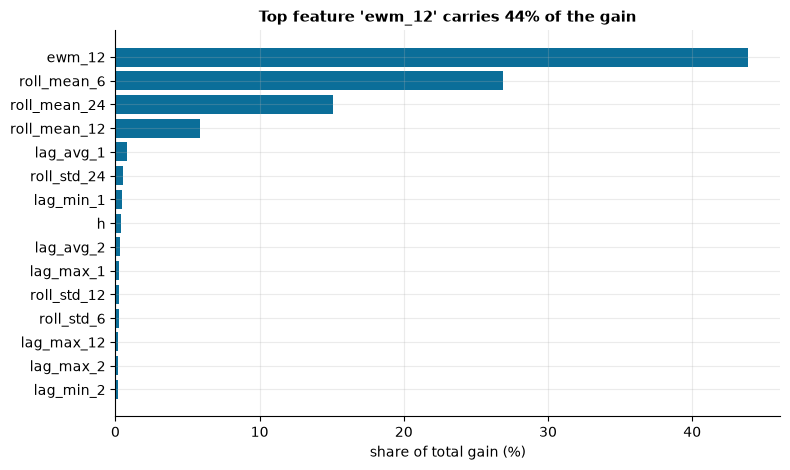

In [17]:
lg = LightGBMPanel(); lg.predict(train, CPU, H)
imp = pd.Series(lg.model_.feature_importance("gain"), index=lg.feature_names_).sort_values(ascending=False)
top15 = (imp / imp.sum() * 100).head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(top15.index, top15.values, color=ACCENT); ax.set(xlabel="share of total gain (%)", title=f"Top feature '{top15.index[-1]}' carries {top15.iloc[-1]:.0f}% of the gain")
save(fig, "08_lightgbm_importance")

## 9. Uncertainty and capacity policy

**Why it matters operationally:** the selected point model is persistence itself and no candidate significantly beat it, so the value is
in how much headroom to buy. Intervals are split-conformal from the selected model's fold residuals; under-provisioning
is priced 10x over-provisioning (devlog D23).

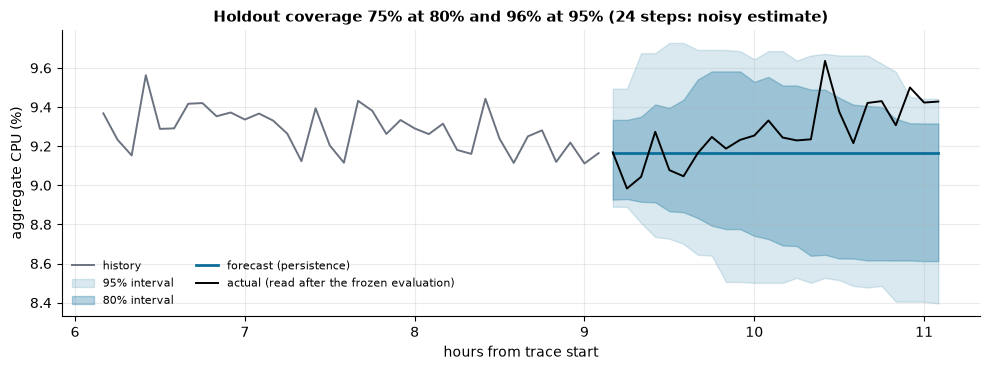

80% misses: 6 of 24 (above 6, below 0); mean position of an above-interval miss: step 21 of 24. 95% misses: above 1, below 0.
Intervals are asymmetric: mean upper half-width 0.28 pp vs lower 0.43 pp (80%).


In [18]:
iv = pd.read_csv(ART / "intervals.csv"); d = iv[iv.target == CPU].sort_values("timestamp")
h_ts = (d.timestamp.to_numpy() - panel.timestamps[0]) / 3600
actual_ho = cpu[n_tr:]
fig, ax = plt.subplots(figsize=(10, 3.8))
ctx = slice(n_tr - 36, n_tr)
ax.plot(hours[ctx], cpu[ctx], color=GREY, lw=1.4, label="history")
ax.fill_between(h_ts, d.lo95, d.hi95, color=ACCENT, alpha=0.15, label="95% interval")
ax.fill_between(h_ts, d.lo80, d.hi80, color=ACCENT, alpha=0.30, label="80% interval")
ax.plot(h_ts, d.point, color=ACCENT, lw=2, label=f"forecast ({chosen})")
ax.plot(h_ts, actual_ho, color="k", lw=1.4, label="actual (read after the frozen evaluation)")
cov80 = np.mean((d.lo80.to_numpy() <= actual_ho) & (actual_ho <= d.hi80.to_numpy()))
cov95 = np.mean((d.lo95.to_numpy() <= actual_ho) & (actual_ho <= d.hi95.to_numpy()))
ax.set(xlabel="hours from trace start", ylabel="aggregate CPU (%)", title=f"Holdout coverage {cov80:.0%} at 80% and {cov95:.0%} at 95% (24 steps: noisy estimate)")
ax.legend(frameon=False, fontsize=8, ncol=2)
save(fig, "09_holdout_intervals")
up80 = actual_ho > d.hi80.to_numpy(); dn80 = actual_ho < d.lo80.to_numpy()
print(f"80% misses: {int((up80 | dn80).sum())} of {len(up80)} (above {int(up80.sum())}, below {int(dn80.sum())}); "
      f"mean position of an above-interval miss: step {np.flatnonzero(up80).mean() + 1:.0f} of {len(up80)}. "
      f"95% misses: above {int((actual_ho > d.hi95.to_numpy()).sum())}, below {int((actual_ho < d.lo95.to_numpy()).sum())}.")
print(f"Intervals are asymmetric: mean upper half-width {np.mean(d.hi80 - d.point):.2f} pp vs lower {np.mean(d.point - d.lo80):.2f} pp (80%).")

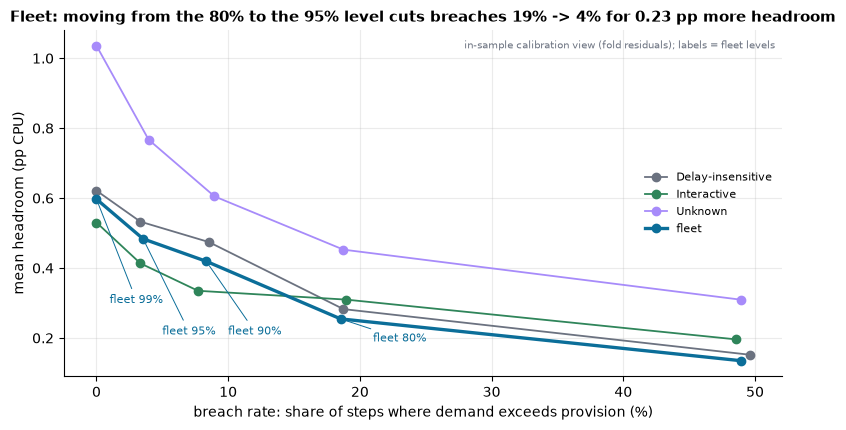

,segment,level,breach_rate,mean_headroom,expected_cost
0,fleet,0.50,0.490,0.135,1.083
1,fleet,0.80,0.185,0.255,0.589
2,fleet,0.90,0.083,0.419,0.466
3,fleet,0.95,0.035,0.483,0.494
4,fleet,0.99,0.000,0.597,0.597
5,Delay-insensitive,0.50,0.496,0.152,1.214
6,Delay-insensitive,0.80,0.188,0.283,0.650
7,Delay-insensitive,0.90,0.085,0.474,0.510
8,Delay-insensitive,0.95,0.033,0.533,0.534
9,Delay-insensitive,0.99,0.000,0.621,0.621


In [19]:
tr = pd.read_csv(ART / "tradeoff.csv")
fig, ax = plt.subplots(figsize=(8, 4.4))
palette = {"fleet": ACCENT, "Delay-insensitive": GREY, "Interactive": "#2f855a", "Unknown": "#a78bfa"}
for seg, g in tr.groupby("segment"):
    ax.plot(g.breach_rate * 100, g.mean_headroom, marker="o", color=palette.get(seg, GREY), lw=2.4 if seg == "fleet" else 1.3, label=seg, zorder=5 if seg == "fleet" else 2)
fl = tr[tr.segment == "fleet"].set_index("level")
pos = {0.99: (1.0, 0.30), 0.95: (5.0, 0.21), 0.9: (10.0, 0.21), 0.8: (21.0, 0.19)}  # clear area below the curves
for lv, xy in pos.items():
    ax.annotate(f"fleet {lv:.0%}", (fl.loc[lv, "breach_rate"] * 100, fl.loc[lv, "mean_headroom"]), xytext=xy, fontsize=8, color=ACCENT,
                arrowprops=dict(arrowstyle="-", color=ACCENT, lw=0.7, shrinkA=2, shrinkB=4))
ax.set(xlabel="breach rate: share of steps where demand exceeds provision (%)", ylabel="mean headroom (pp CPU)",
       title=f"Fleet: moving from the 80% to the 95% level cuts breaches {fl.loc[0.8, 'breach_rate']:.0%} -> {fl.loc[0.95, 'breach_rate']:.0%} for {fl.loc[0.95, 'mean_headroom'] - fl.loc[0.8, 'mean_headroom']:.2f} pp more headroom")
ax.text(0.99, 0.97, "in-sample calibration view (fold residuals); labels = fleet levels", transform=ax.transAxes, ha="right", va="top", fontsize=7, color=GREY)
ax.legend(frameon=False, fontsize=8, loc="center right")
save(fig, "09_tradeoff")
tr.round(3)

In [20]:
cp = pd.read_csv(ART / "capacity_plan.csv")
cp.assign(head90=cp.upper_90 - cp.point, head95=cp.upper_95 - cp.point).groupby("segment").agg(
    point_mean=("point", "mean"), upper_90_mean=("upper_90", "mean"), upper_95_mean=("upper_95", "mean"),
    headroom_90=("head90", "mean"), headroom_95=("head95", "mean")).round(3)

,point_mean,upper_90_mean,upper_95_mean,headroom_90,headroom_95
segment,,,,,
Delay-insensitive,7.933,8.263,8.350,0.330,0.417
Interactive,11.416,11.637,11.736,0.222,0.320
Unknown,8.330,8.699,8.897,0.369,0.568
fleet,9.038,9.302,9.390,0.265,0.352


The capacity plan provisions to the conformal upper bound of core-weighted CPU for each segment. The trade-off
curves are calibration views (offsets are fitted on the same fold residuals they are scored on), not out-of-sample
guarantees. Interactive VMs are latency-sensitive, so they get their own row.

## 10. Holdout result (single evaluation)

`holdout_eval.json` was written once by `cwfc.evaluate` after the model and selection were frozen; it is read
here, never recomputed.

In [21]:
ho = pd.DataFrame(json.loads((ART / "holdout_eval.json").read_text())).T
m = ho.loc[CPU]
print(f"{CPU}: MAE {m.mae:.3f} pp (persistence {m.persistence_mae:.3f}), MASE {m.mase:.2f}, "
      f"peak-quartile MAE {m.peak_quartile_mae:.3f} pp, coverage {m.coverage80:.2f} @80%, {m.coverage95:.2f} @95%")
print(f"Training-fold MAE of the same model: {bs.loc[bs.model == chosen, 'mae'].iloc[0]:.3f} pp")
ho.round(4)

aggregate_cpu_utilization: MAE 0.147 pp (persistence 0.147), MASE 1.21, peak-quartile MAE 0.309 pp, coverage 0.75 @80%, 0.96 @95%
Training-fold MAE of the same model: 0.243 pp


,mae,rmse,mase,persistence_mae,rel_mae_vs_persistence,peak_quartile_mae,coverage80,coverage95
active_vm_count,0.0000,0.0000,0.0000,0.0000,NaN,0.0000,1.00,1.0000
aggregate_cpu_utilization,0.1468,0.1848,1.2119,0.1468,1.0,0.3085,0.75,0.9583


The holdout MAE is lower than the fold MAE, plausibly because the holdout window sits after the bump (half the fold origins, 10 of 20, sit on it); 24 points are far too few to rank models, which is why selection used the 20 training folds.